## Chapter 4: Hot and Cold Learning

### Learning by adjusting weights

Until now, our neural networks have used fixed weights
to make predictions.

**Learning** means finding weights that produce more
accurate predictions.

Hot and cold learning is a simple approach: adjust
a weight slightly, measure whether the prediction
improves, and keep moving in the better direction.

### Measuring error

The network calculates a prediction:

$$
\text{prediction} = \text{input} \times \text{weight}
$$

It compares the prediction against the correct
value (`goal_prediction`) using **squared error**:

$$
\text{error} = (\text{prediction} - \text{goal})^2
$$

Squaring makes the error nonnegative and penalizes
larger differences more heavily.

### Finding a better weight

1. Calculate the prediction and its error.
2. Try increasing the weight slightly.
3. Try decreasing the weight slightly.
4. Compare the resulting errors.
5. Keep the adjustment that produces the smaller error.

The amount by which we test the weight is called
the `step_amount`.

### Key idea

The network is no longer simply producing predictions.
It is **evaluating its predictions and modifying a
weight to reduce error**.

This is a simple form of numerical optimization.
Later, gradient descent will provide a more efficient
way of determining how to change weights.

In [2]:
# Chapter 4: Measuring prediction error

weight = 0.1

toes = [8.5, 9.5, 9.9, 9.0]
win_or_lose_binary = [1, 1, 0, 1]

input = toes[0]
goal_prediction = win_or_lose_binary[0]

# Make a prediction
prediction = input * weight

# Calculate squared error
error = (prediction - goal_prediction) ** 2

print("Prediction:", prediction)
print("Goal:", goal_prediction)
print("Error:", error)

Prediction: 0.8500000000000001
Goal: 1
Error: 0.022499999999999975


In [3]:
# Hot and cold learning: one weight adjustment

weight = 0.1
step_amount = 0.01

input = 8.5
goal_prediction = 1

# Original prediction and error
prediction = input * weight
error = (prediction - goal_prediction) ** 2

# Try increasing the weight
up_prediction = input * (weight + step_amount)
up_error = (up_prediction - goal_prediction) ** 2

# Try decreasing the weight
down_prediction = input * (weight - step_amount)
down_error = (down_prediction - goal_prediction) ** 2

print("Original error:", round(error, 6))
print("Error if weight increases:", round(up_error, 6))
print("Error if weight decreases:", round(down_error, 6))

# Choose the direction with lower error
if up_error < down_error:
    weight += step_amount
else:
    weight -= step_amount

print("New weight:", round(weight, 4))

Original error: 0.0225
Error if weight increases: 0.004225
Error if weight decreases: 0.055225
New weight: 0.11


## One Iteration of Gradient Descent

Hot-and-cold learning tests different weights to see
which produces less error. **Gradient descent**
instead calculates how the weight should change
to reduce error.

For a single-weight network:

$$
\text{prediction} = \text{input} \times \text{weight}
$$

$$
\text{error} = (\text{prediction} - \text{goal})^2
$$

The slope of the error with respect to the weight is:

$$
\frac{dE}{dw} =
2(\text{prediction} - \text{goal})\times\text{input}
$$

In the book's simplified update, the factor of
2 is omitted:

$$
\text{direction\_and\_amount} =
(\text{prediction} - \text{goal})\times\text{input}
$$

$$
\text{weight}_{new} =
\text{weight}_{old} - \text{direction\_and\_amount}
$$

The sign determines the direction of the adjustment,
while the magnitude determines its size.

**Key idea:** Gradient descent replaces trial-and-error
comparisons with a calculated weight adjustment.

## Learning Is Reducing Error: Derivatives and Convergence

A neural network learns by adjusting its **weights**
to reduce the difference between its predictions
and the target values.

For a simple network:

$$
\text{prediction} = \text{input} \times \text{weight}
$$

$$
\text{error} = (\text{prediction} - \text{goal})^2
$$

The input and goal are fixed during an individual
training step. The weight is the parameter we adjust.

### Understanding the derivative

The derivative measures how sensitive the error
is to a change in weight:

$$
\frac{dE}{dw} =
2(\text{prediction} - \text{goal})\times\text{input}
$$

- **Negative derivative:** Increasing the weight
  locally reduces error.
- **Positive derivative:** Decreasing the weight
  locally reduces error.
- **Derivative near zero:** The error curve is
  nearly flat.

Gradient descent moves in the opposite direction
to the derivative:

$$
w_{new} = w_{old} - \alpha\frac{dE}{dw}
$$

Here, $\alpha$ is the learning rate.

### Convergence

Repeated adjustments can bring the weight closer
to the value that minimizes error.

With input $0.5$ and target $0.8$, the optimal
weight is:

$$
w = \frac{0.8}{0.5} = 1.6
$$

**Key idea:** The derivative provides a direction
for reducing error without testing every possible
weight.

Iteration  0: Weight = 0.7750, Error = 0.302500
Iteration  1: Weight = 0.9813, Error = 0.170156
Iteration  2: Weight = 1.1359, Error = 0.095713
Iteration  3: Weight = 1.2520, Error = 0.053839
Iteration  4: Weight = 1.3390, Error = 0.030284
Iteration  5: Weight = 1.4042, Error = 0.017035
Iteration  6: Weight = 1.4532, Error = 0.009582
Iteration  7: Weight = 1.4899, Error = 0.005390
Iteration  8: Weight = 1.5174, Error = 0.003032
Iteration  9: Weight = 1.5381, Error = 0.001705
Iteration 10: Weight = 1.5535, Error = 0.000959
Iteration 11: Weight = 1.5652, Error = 0.000540
Iteration 12: Weight = 1.5739, Error = 0.000304
Iteration 13: Weight = 1.5804, Error = 0.000171
Iteration 14: Weight = 1.5853, Error = 0.000096
Iteration 15: Weight = 1.5890, Error = 0.000054
Iteration 16: Weight = 1.5917, Error = 0.000030
Iteration 17: Weight = 1.5938, Error = 0.000017
Iteration 18: Weight = 1.5953, Error = 0.000010
Iteration 19: Weight = 1.5965, Error = 0.000005


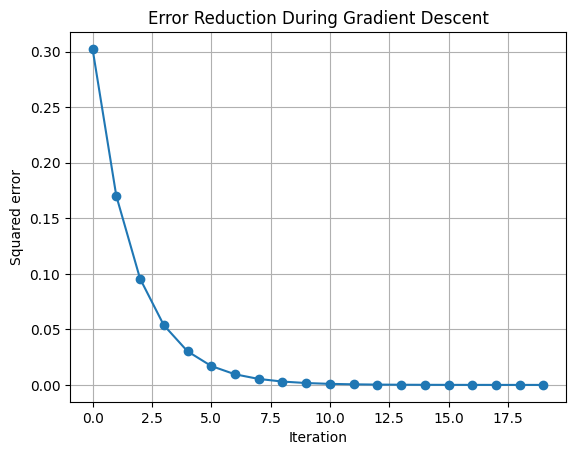

In [4]:
import matplotlib.pyplot as plt

weight = 0.5
input_value = 0.5
goal_prediction = 0.8

weights_history = []
errors_history = []

for iteration in range(20):
    prediction = input_value * weight
    error = (prediction - goal_prediction) ** 2

    weights_history.append(weight)
    errors_history.append(error)

    # Simplified gradient used in the book
    direction_and_amount = (prediction - goal_prediction) * input_value

    weight -= direction_and_amount

    print(f"Iteration {iteration:2d}: "
          f"Weight = {weight:.4f}, Error = {error:.6f}")

# Visualize learning
plt.plot(range(20), errors_history, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Squared error")
plt.title("Error Reduction During Gradient Descent")
plt.grid(True)
plt.show()

## Learning Rates, Overshooting, and Divergence

Gradient descent uses the derivative of the error
to determine how to adjust a weight.

However, knowing the correct direction does not
guarantee that the adjustment will be successful.

### Overshooting and divergence

If the weight adjustment is too large, it can pass
beyond the minimum of the error function. This is
called **overshooting**.

Repeated overshooting can cause the error to
increase rather than decrease. This is called
**divergence**.

### The learning rate (alpha)

The learning rate, usually written as $\alpha$,
controls the size of each weight adjustment:

$$
w_{new} = w_{old} - \alpha \frac{dE}{dw}
$$

- A large learning rate can cause overshooting.
- A small learning rate produces smaller steps,
  but may learn slowly.
- A suitable learning rate allows the network
  to approach a minimum efficiently.

In *Grokking Deep Learning*, the examples initially
use a simplified gradient that omits the factor of 2.

### Key takeaway

The derivative tells us **which direction** to move
and how steep the error curve is.

The learning rate controls **how far** we move.

Learning requires both a useful gradient and an
appropriately sized weight adjustment.

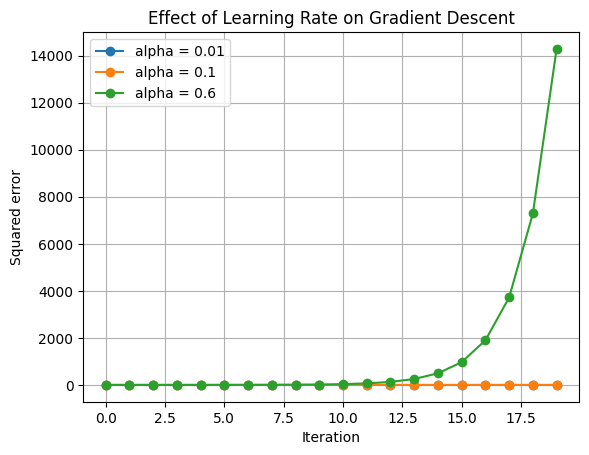

In [5]:
import matplotlib.pyplot as plt

def train_network(alpha, iterations=20):
    weight = 0.5
    input_value = 2.0
    goal_prediction = 0.8

    errors = []

    for i in range(iterations):
        prediction = input_value * weight
        error = (prediction - goal_prediction) ** 2

        errors.append(error)

        # Simplified gradient from the book
        derivative = (prediction - goal_prediction) * input_value

        weight -= alpha * derivative

    return errors


# Compare three learning rates
for alpha in [0.01, 0.1, 0.6]:
    errors = train_network(alpha)
    plt.plot(errors, marker="o", label=f"alpha = {alpha}")

plt.xlabel("Iteration")
plt.ylabel("Squared error")
plt.title("Effect of Learning Rate on Gradient Descent")
plt.legend()
plt.grid(True)
plt.show()